## Labels vs. Scale: Breaking Even on Banking77 with Encoders and Decoders

#### Results

This notebook only **displays** results. All logic lives in `scripts/evaluation.py`, which every model script also uses, so the files are written, checked and scored the same way everywhere.

Every model run writes one prediction CSV per split to `results/`, following `results/PREDICTION_FORMAT.md`. A file that breaks the format stops the scoring with a list of every problem found.

**Ground rules**
- Tune on `val`, report on `test`.
- An unmatched decoder answer (`-1`) counts as wrong. It is never dropped.

#### Setup

In [8]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

import pandas as pd

# Find the project root (the folder that contains scripts/download_data.py), wherever the kernel starts
cwd = Path.cwd().resolve()
ROOT = next((p for p in [cwd, *cwd.parents] if (p / "scripts" / "download_data.py").exists()), cwd)

# Make scripts/ importable, then load the shared evaluation module

sys.path.insert(0, str(ROOT / "scripts"))
import evaluation as ev

FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

REPORTS = ev.ROOT / "reports"
REPORTS.mkdir(exist_ok=True)

print("Prediction files in results/:", len(list(ev.RESULTS.glob("*.csv"))))

def natural_order(summary):
    # For display only: sort by model, then by budget size (k1, k3, ..., full) instead of alphabetically
    order = [b for b in ev.BUDGETS if b in summary["budget"].unique()]
    out = summary.copy()
    out["budget"] = pd.Categorical(out["budget"], categories=order, ordered=True)
    return out.sort_values(["model", "budget"]).reset_index(drop=True)


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Prediction files in results/: 292


#### Validation scores
The same scoring on the validation split. Use these to tune, and use the test scores above only for the final numbers.

In [9]:
val_summary = ev.summarize(ev.score_all("val"))
natural_order(val_summary).round(3)

,model,type,budget,accuracy_mean,accuracy_std,macro_f1_mean,macro_f1_std,n_seeds
0,frontier,decoder,zeroshot,0.894,NaN,0.889,NaN,1
1,majority,baseline,k1,0.013,0.000,0.000,0.000,3
2,majority,baseline,k3,0.013,0.000,0.000,0.000,3
3,majority,baseline,k5,0.013,0.000,0.000,0.000,3
4,majority,baseline,k10,0.013,0.000,0.000,0.000,3
5,majority,baseline,k20,0.013,0.000,0.000,0.000,3
6,majority,baseline,k30,0.013,0.000,0.000,0.000,3
7,majority,baseline,p50,0.013,0.000,0.000,0.000,3
8,majority,baseline,full,0.013,0.000,0.000,0.000,3
9,modernbert,encoder,k1,0.074,0.033,0.057,0.030,3


#### Score every run
`score_all` loads each `*_test.csv`, checks it against the format, and scores it. `summarize` then gives the mean and standard deviation across seeds for each model and budget.

In [10]:
# One row per run, then mean and standard deviation across seeds
scores = ev.score_all("test")
summary = natural_order(ev.summarize(scores)).round(3)

# Save next to the prediction files. ev.RESULTS is the project's results folder, so this works from any notebook folder
summary.to_csv(REPORTS / "summary_test.csv", index=False)
print("Saved:", REPORTS / "summary_test.csv")

summary


Saved: /Users/chandu/Desktop/Term3-Fall2026/266-NLP/Final Project/DATASCI266-Banking77-Encoder-vs-Decoder/reports/summary_test.csv


,model,type,budget,accuracy_mean,accuracy_std,macro_f1_mean,macro_f1_std,n_seeds
0,frontier,decoder,zeroshot,0.880,NaN,0.877,NaN,1
1,majority,baseline,k1,0.013,0.000,0.000,0.000,3
2,majority,baseline,k3,0.013,0.000,0.000,0.000,3
3,majority,baseline,k5,0.013,0.000,0.000,0.000,3
4,majority,baseline,k10,0.013,0.000,0.000,0.000,3
5,majority,baseline,k20,0.013,0.000,0.000,0.000,3
6,majority,baseline,k30,0.013,0.000,0.000,0.000,3
7,majority,baseline,p50,0.013,0.000,0.000,0.000,3
8,majority,baseline,full,0.013,0.000,0.000,0.000,3
9,modernbert,encoder,k1,0.083,0.040,0.065,0.039,3


#### Results table
Mean test score per budget and model, in percent. The best value in each column is in bold. A dash means that model has no run for that budget. The images are saved to `reports/figures/` for the report.

In [11]:
import matplotlib.pyplot as plt

# Models shown as rows, in this order, with the names used in the table (delete a line to hide a model)
TABLE_MODELS = {
    "modernbert": "ModernBERT fixed3",
    "modernbert_min300": "ModernBERT min300",
    "modernbert_min600": "ModernBERT min600",
    "qwen_sft": "Qwen2.5-1.5B fine-tuned",
    "tfidf_lr": "TF-IDF + LR",
    "majority": "Majority class",
    "qwen_zeroshot": "Qwen2.5-1.5B zero-shot",
    "frontier": "Claude Opus 5.5 zero-shot",
}

def build_results_table(summary, metric="accuracy", models=TABLE_MODELS):
    """Rows = models, columns = budgets, values = mean score in percent (one decimal). Missing runs are NaN."""
    col = f"{metric}_mean"
    flat = summary.assign(budget=summary["budget"].astype(str))          # Plain strings, not the sorted categorical
    wide = flat.pivot(index="model", columns="budget", values=col) * 100
    cols = [b for b in ev.BUDGETS if b in wide.columns]                  # zeroshot, k1, k3, ..., full
    keep = [m for m in models if m in wide.index]                        # Only models that have results
    wide = wide.reindex(index=keep, columns=cols).round(1)
    wide = wide.dropna(axis=1, how="all")                                # Drop budgets with no result (e.g. zero-shot column when no zero-shot model is shown)
    wide.index = [models[m] for m in keep]
    wide.columns = ["Zero-shot" if b == "zeroshot" else b for b in wide.columns]
    wide.index.name = "Model \\ Budget"                                  # Shows both the row and the column name in the top-left cell
    return wide

def style_results_table(table):
    """Notebook view: percent with one decimal, the best value in each column in bold ('–' = no run)."""
    def bold_max(column):
        return ["font-weight: bold" if (pd.notna(v) and v == column.max()) else "" for v in column]
    return table.style.apply(bold_max, axis=0).format("{:.1f}%", na_rep="–")

def save_results_table_png(table, path, title=None, dpi=200):
    """Draw the table as an image with the best value in each column in bold, and save it."""
    text = [[("–" if pd.isna(v) else f"{v:.1f}%") for v in row] for row in table.values]
    fig, ax = plt.subplots(figsize=(3.2 + 1.0 * len(table.columns), 0.33 * len(table) + 1.1))
    ax.axis("off")
    tbl = ax.table(cellText=text, rowLabels=list(table.index), colLabels=list(table.columns),
                   cellLoc="center", loc="upper center")
    tbl.auto_set_font_size(False)
    tbl.set_fontsize(10)
    tbl.auto_set_column_width(list(range(-1, len(table.columns))))      # Column -1 is the row-label column
    tbl.scale(1, 1.6)
    corner = tbl.add_cell(0, -1, width=tbl[1, -1].get_width(), height=tbl[0, 0].get_height(),
                          text=table.index.name or "Model", loc="center", facecolor="#eeeeee")   # Top-left header cell
    corner.set_text_props(fontweight="bold")
    for j in range(len(table.columns)):                                  # Header row: bold, light grey
        tbl[0, j].set_text_props(fontweight="bold")
        tbl[0, j].set_facecolor("#eeeeee")
    for j, name in enumerate(table.columns):                             # Table row 0 is the header, data starts at 1
        best = table[name].max()
        for i, v in enumerate(table[name], start=1):
            if pd.notna(v) and v == best:
                tbl[i, j].set_text_props(fontweight="bold")
    if title:
        ax.set_title(title, fontsize=11, pad=8)
    fig.savefig(path, dpi=dpi, bbox_inches="tight")
    plt.close(fig)
    return path

In [12]:
# Accuracy table: shown here, then saved as an image for the report
acc_table = build_results_table(summary, "accuracy")
display(style_results_table(acc_table))
path = save_results_table_png(acc_table, FIG / "results_table_accuracy.png",
                              title="Test accuracy (%), mean of 3 seeds; best in each column in bold")
print("Saved:", path)

# Macro-F1 table, same layout
f1_table = build_results_table(summary, "macro_f1")
display(style_results_table(f1_table))
path = save_results_table_png(f1_table, FIG / "results_table_macro_f1.png",
                              title="Test macro-F1 (%), mean of 3 seeds; best in each column in bold")
print("Saved:", path)

,Zero-shot,k1,k3,k5,k10,k20,k30,p50,full
Model \ Budget,,,,,,,,,
ModernBERT fixed3,–,8.3%,17.7%,52.4%,78.0%,86.5%,89.4%,92.1%,93.6%
ModernBERT min300,–,22.3%,52.0%,64.4%,80.0%,87.1%,89.4%,92.1%,93.6%
ModernBERT min600,–,22.2%,51.3%,65.5%,79.4%,87.3%,89.6%,92.1%,93.6%
Qwen2.5-1.5B fine-tuned,–,49.3%,64.6%,74.4%,83.1%,88.0%,90.8%,92.4%,93.9%
TF-IDF + LR,–,28.4%,48.4%,56.7%,68.4%,76.2%,79.9%,84.7%,87.0%
Majority class,–,1.3%,1.3%,1.3%,1.3%,1.3%,1.3%,1.3%,1.3%
Qwen2.5-1.5B zero-shot,42.1%,–,–,–,–,–,–,–,–
Claude Opus 5.5 zero-shot,88.0%,–,–,–,–,–,–,–,–


Saved: /Users/chandu/Desktop/Term3-Fall2026/266-NLP/Final Project/DATASCI266-Banking77-Encoder-vs-Decoder/reports/figures/results_table_accuracy.png


,Zero-shot,k1,k3,k5,k10,k20,k30,p50,full
Model \ Budget,,,,,,,,,
ModernBERT fixed3,–,6.5%,14.6%,52.1%,77.7%,86.5%,89.4%,92.1%,93.6%
ModernBERT min300,–,20.8%,51.3%,63.9%,80.0%,87.1%,89.4%,92.1%,93.6%
ModernBERT min600,–,21.0%,50.7%,65.3%,79.3%,87.3%,89.6%,92.1%,93.6%
Qwen2.5-1.5B fine-tuned,–,50.8%,66.0%,75.0%,83.7%,88.4%,91.1%,92.5%,94.0%
TF-IDF + LR,–,27.1%,47.3%,55.5%,67.9%,76.0%,79.7%,84.7%,86.9%
Majority class,–,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%
Qwen2.5-1.5B zero-shot,39.9%,–,–,–,–,–,–,–,–
Claude Opus 5.5 zero-shot,87.7%,–,–,–,–,–,–,–,–


Saved: /Users/chandu/Desktop/Term3-Fall2026/266-NLP/Final Project/DATASCI266-Banking77-Encoder-vs-Decoder/reports/figures/results_table_macro_f1.png


### Are all runs there?
Seeds found for each model and budget. A missing run shows as `NaN`; zero-shot models should have exactly 1 seed.

In [13]:
# Columns in budget order, only the budgets that exist
order = [b for b in ev.BUDGETS if b in summary["budget"].unique()]
summary.pivot(index="model", columns="budget", values="n_seeds")[order]

budget,zeroshot,k1,k3,k5,k10,k20,k30,p50,full
model,,,,,,,,,
frontier,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
majority,NaN,3.0,3.0,3.0,3.0,3.0,3.0,3.0,3.0
modernbert,NaN,3.0,3.0,3.0,3.0,3.0,3.0,3.0,3.0
modernbert_min300,NaN,3.0,3.0,3.0,3.0,3.0,3.0,3.0,3.0
modernbert_min600,NaN,3.0,3.0,3.0,3.0,3.0,3.0,3.0,3.0
qwen_sft,NaN,3.0,3.0,3.0,3.0,3.0,3.0,3.0,3.0
qwen_zeroshot,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tfidf_lr,NaN,3.0,3.0,3.0,3.0,3.0,3.0,3.0,3.0


#### Learning curves
Score against the number of training examples (log scale). Where the encoder and decoder lines cross is the break-even point. The shaded band is one standard deviation across seeds. Zero-shot models are flat dashed lines. The figures are also saved to `reports/figures/`.

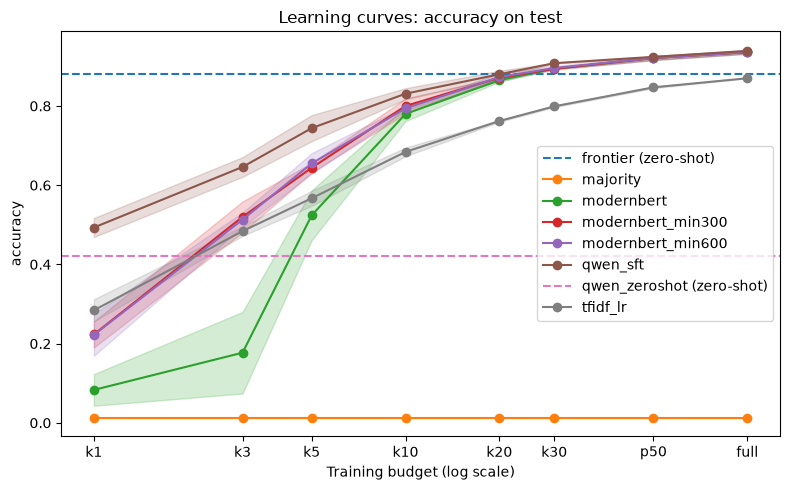

In [14]:
# Accuracy (primary metric)
ev.plot_learning_curve(summary, "accuracy", save_to=FIG / "learning_curve_accuracy.png")

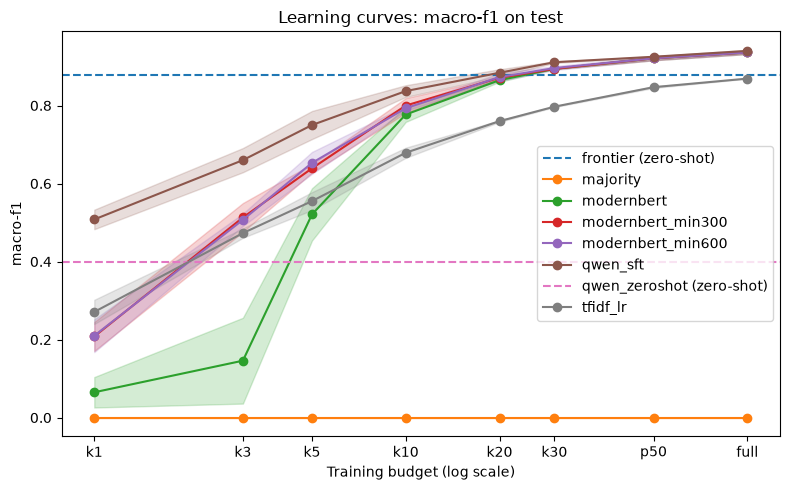

In [15]:
# Macro-F1 (secondary metric)
ev.plot_learning_curve(summary, "macro_f1", save_to=FIG / "learning_curve_macro_f1.png")

#### Look inside one run
Change `RUN` to any file in `results/`. The first table shows the ten weakest intents. The second shows the most frequent mistakes (an unmatched decoder answer appears as `unmatched`).

In [16]:
# Any prediction file in results/

# RUN = "majority_full_seed0_test.csv"
RUN = "tfidf_lr_full_seed0_test.csv"

df = ev.load_predictions(ev.RESULTS / RUN)
print("Run:", RUN)
print("Scores:", ev.score(df))

# The ten intents with the lowest F1
ev.per_intent(df).sort_values("f1").head(10)

Run: tfidf_lr_full_seed0_test.csv
Scores: {'accuracy': 0.8698051948051948, 'macro_f1': 0.8692678224375207}


,intent,precision,recall,f1,support
72,virtual_card_not_working,1.000000,0.325,0.490566,40
5,balance_not_updated_after_bank_transfer,0.620000,0.775,0.688889,40
37,get_disposable_virtual_card,0.673913,0.775,0.720930,40
14,card_not_working,0.625000,0.875,0.729167,40
16,card_payment_not_recognised,0.680851,0.800,0.735632,40
74,why_verify_identity,0.777778,0.700,0.736842,40
69,verify_my_identity,0.695652,0.800,0.744186,40
48,pending_transfer,0.800000,0.700,0.746667,40
61,top_up_reverted,0.775000,0.775,0.775000,40
34,extra_charge_on_statement,0.723404,0.850,0.781609,40


In [17]:
# The ten most frequent mistakes: true intent -> predicted intent
ev.top_confusions(df, 10)

,true,predicted,count
0,virtual_card_not_working,get_disposable_virtual_card,13
1,why_verify_identity,verify_my_identity,9
2,virtual_card_not_working,getting_virtual_card,6
3,card_acceptance,card_not_working,6
4,card_swallowed,declined_cash_withdrawal,6
5,top_up_reverted,top_up_failed,6
6,unable_to_verify_identity,verify_my_identity,5
7,request_refund,Refund_not_showing_up,5
8,transfer_timing,balance_not_updated_after_bank_transfer,4
9,fiat_currency_support,exchange_via_app,4
